# Бие даалт — Монголын шилэн кабелийн сүлжээ

**Зорилго:** 22 хотын трассын өртгийг тооцож, MST, bridge-гүй нөөцтэй сүлжээ, full mesh-ийг харьцуулах; кабель тасрахад нөөц зам, тусгаарлагдах хот, хоцролтыг шалгах.

Энэ notebook нь шинэ Flask/React вебтэй **ижил газарзүй, ижил алгоритмын модулийг** ашиглана. Өгсөн эх ажил `BiyDaalt/Biydaalt.ipynb` тусдаа хэвээр. Картын шугамууд нь улсын хэмжээний симуляцийн трасс; бодит авто замын хэмжилт биш.

**Ажиллуулах:** `Python (Сүлжээний загварчлал)` kernel → **Restart Kernel and Run All**. Нэг нүд: **Shift+Enter**. Хадгалах: **Ctrl+S**.

Веб нээх команд (Terminal):
```bash
bash run-fiber-atlas.sh    # репозиторийн язгуур директороос
```

## 1. Орчин, эх өгөгдөл

Natural Earth-ийн хил, аймаг, 14 нуур, 4 уулын бүс, 7 голын геометр ашиглана. Хотын солбицол ба ой нь эх notebook-ийн өгөгдөл. 5 км метрийн тор, бүх хэрчмийн geometry validation-тай. Өртөг нь ой болон төлөвлөсөн голын гарцын нэмэлт өртгийг тооцно.

In [1]:
from pathlib import Path
import sys, json, math, time
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'fiberlab/engine.py').exists())
sys.path.insert(0,str(root))
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from fiberlab.terrain import TerrainRouter, geodesic_km
from fiberlab.engine import NetworkModel, tarjan_bridges
from shapely.geometry import shape

cache=json.loads((root/'data/routes.cache.json').read_text())
assert cache['fingerprint']==TerrainRouter.fingerprint(cache['cities'])
model=NetworkModel(cache['cities'],cache['routes'])
names={k:v['name'] for k,v in model.cities.items()}
print('Python:',sys.version.split()[0], 'NetworkX:',nx.__version__)
print('Хот:',len(model.cities),'Боломжит трасс:',len(model.routes))
print('Топологийн тооцоо:',round(model.compute_ms,2),'мс')

Python: 3.12.14 NetworkX: 3.7
Хот: 22 Боломжит трасс: 231
Топологийн тооцоо: 22.46 мс


## 2. Prim MST → MILP нөөц холбоос

MST нь бүх хотыг холбосон мод тул 22−1=21 кабельтай; бүх холбоос нь bridge. Prim-ийн жин нь terrain-weighted `cost_km`. Нэмэлт кабель сонгох бинар MILP нь MST-ийн холбоос бүрийг дор хаяж нэг cycle-д багтаах нөхцөлтэй. Энэ нь сонгосон MST дээрх хамгийн бага нэмэлт өртөг; бүх боломжит 2-edge сүлжээний глобал оптимум биш.

RTT нь хоёр талын тархалтын хугацааны **тооцоо**: `2 × урт_км × 5 / 1000` мс. Төхөөрөмжийн processing, queueing, throughput хэмжээгүй.

In [2]:
summary=pd.DataFrame([
    {'Топологи':key,'Кабель':s['edges'],'Урт (км)':round(s['km'],1),
     'Өртөг (weighted-км)':round(s['cost_km'],1),'Bridge':s['bridge_count'],
     'RTT (мс)':round(s['rtt_ms'],2),'Нэмэлт урт (%)':round(s['overhead_pct'],1),
     'Нэг тасралт даах':s['fault_tolerant']}
    for key,s in model.stats.items()
])
display(summary)
print('MILP төлөв:',model.optimization['status'],'gap:',model.optimization['gap'])
display(pd.DataFrame([
    {'Нэмэлт кабель':names[r['u']]+' — '+names[r['v']], 'Урт (км)':round(r['distance_km'],1),
     'Төлөвлөсөн голын гарц':len(r['river_crossings'])}
    for r in model.routes.values() if r['id'] in model.optimization['added']
]))

,Топологи,Кабель,Урт (км),Өртөг (weighted-км),Bridge,RTT (мс),Нэмэлт урт (%),Нэг тасралт даах
0,mst,21,5889.1,7284.1,21,38.49,0.0,False
1,protected,27,9087.7,11239.3,0,28.29,54.3,True
2,full,231,214426.9,240893.1,0,21.80,3541.1,True


MILP төлөв: optimal gap: 0.0


,Нэмэлт кабель,Урт (км),Төлөвлөсөн голын гарц
0,Улаанбаатар — Сэлэнгэ,382.2,0
1,Эрдэнэт — Мандалговь,606.6,1
2,Хэнтий — Чойбалсан,579.3,2
3,Мөрөн — Улиастай,567.1,0
4,Даланзадгад — Алтай,782.5,0
5,Өлгий — Ховд,280.8,0


## 3. Газарзүйн трасс ба гурван топологи

MST улаан, 2-edge цэнхэр, full mesh ногоон. Нуур цэнхэр, уулын бүс бор шар. Хотын уулын бүсээс гарах нэвтрэх хэсэг шар тасархай. Голын төлөвлөсөн гарц ногоон цэнхэр тасархай. Зургийн шугамыг хялбаршуулж нуур, уул дээгүүр товчлохгүй.

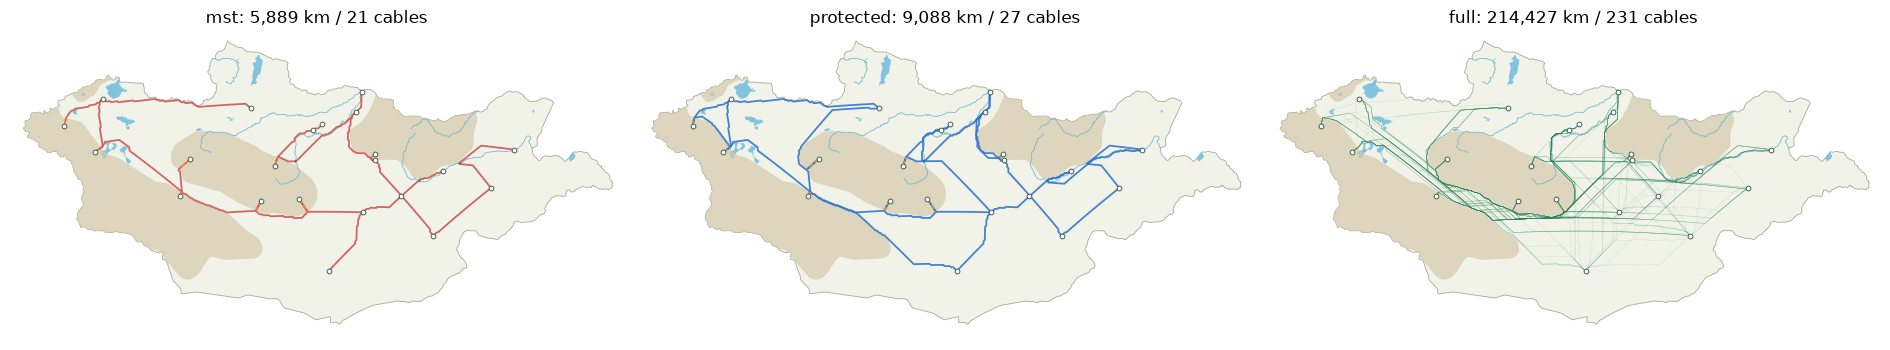

In [3]:
geo=json.loads((root/'data/layers.geojson').read_text())
def draw_geometry(ax,g,**kw):
    if g.is_empty:return
    if g.geom_type=='Polygon':
        x,y=g.exterior.xy;ax.fill(x,y,**kw)
    elif hasattr(g,'geoms'):
        for part in g.geoms:draw_geometry(ax,part,**kw)
    elif g.geom_type=='LineString':
        ax.plot(*g.xy,**kw)

fig,axes=plt.subplots(1,3,figsize=(19,6))
colors={'mst':'#cf5555','protected':'#3276ce','full':'#28865a'}
for ax,(kind,graph) in zip(axes,model.graphs.items()):
    for f in geo['features']:
        k=f['properties']['kind'];g=shape(f['geometry'])
        if k=='country':draw_geometry(ax,g,facecolor='#f1f3e9',edgecolor='#a2ad98',linewidth=.6)
        if k=='mountain':draw_geometry(ax,g,facecolor='#d7c9ac',edgecolor='none',alpha=.7)
        if k=='lake':draw_geometry(ax,g,facecolor='#82c3df',edgecolor='none')
        if k=='river':draw_geometry(ax,g,color='#78b9cd',linewidth=.6)
    for u,v,d in graph.edges(data=True):
        x,y=zip(*d['geometry']);ax.plot(x,y,color=colors[kind],lw=.4 if kind=='full' else 1.3,alpha=.15 if kind=='full' else .9)
        if kind!='full':
            for a in d['access']:
                if a['mountain_access']:
                    x,y=zip(*a['coords']);ax.plot(x,y,color='#df9c2f',ls='--',lw=1)
            for a in d['river_crossings']:
                x,y=zip(*a['coords']);ax.plot(x,y,color='#008987',ls='--',lw=2)
    for n,c in model.cities.items():ax.scatter(c['lon'],c['lat'],s=12,c='white',edgecolors='#284c3b',linewidth=.6,zorder=10)
    ax.set_xlim(87,120.5);ax.set_ylim(41,52.5);ax.set_aspect(1/math.cos(math.radians(47)))
    ax.set_title(f"{kind}: {model.stats[kind]['km']:,.0f} km / {graph.number_of_edges()} cables")
    ax.set_axis_off()
plt.tight_layout();plt.show()

## 4. Нуур, уул, голын геометрийн шалгалт

Зөвхөн зургийг хараад “тойрсон” гэж дүгнэхгүй. Трассын бүх шугам улсын хил дотор, нуур огтлоогүй, үндсэн хэсэг уулыг огтлоогүй, голыг зөвхөн урьдчилан зарласан гарцаар гаталсан эсэхийг шалгана. Mountain polygon дотор байрлах хотын local access нь ил тод онцгой нөхцөл. Голын гарцууд нь **санал болгосон байршил**, бодит гүүрийн бүртгэл биш.

In [4]:
router=TerrainRouter()
checks={r['id']:router.validate_route(r) for r in model.routes.values()}
assert all(all(c.values()) for c in checks.values())
print('Шалгасан трасс:',len(checks),'Зөрчилтэй трасс:',sum(not all(c.values()) for c in checks.values()))
print('Саадгүй торны орой:',len(router.xy),'Голын төлөвлөсөн гарц:',len(router.gates))
access=[]
for key,city in model.cities.items():
    _,a=router.endpoint(city)
    if a['mountain_access']:access.append({'Хот':names[key],'Уулын бүс дэх нэвтрэх хэсэг (км)':round(a['length_km'],1)})
display(pd.DataFrame(access))

Шалгасан трасс: 231 Зөрчилтэй трасс: 0
Саадгүй торны орой: 42499 Голын төлөвлөсөн гарц: 7


,Хот,Уулын бүс дэх нэвтрэх хэсэг (км)
0,Улаанбаатар,23.4
1,Баянхонгор,47.9
2,Арвайхээр,65.4
3,Өлгий,35.3
4,Ховд,33.1
5,Алтай,19.0
6,Цэцэрлэг,40.3
7,Зуунмод,4.1
8,Улиастай,64.4


## 5. Нэг кабель тасрахад

MST-д байгаа нэг ижил кабелийг суурь ба нөөцтэй сүлжээнд тасалж харьцуулна. UB-тай холбоогүй үлдсэн хотуудыг тусгаарлагдсан гэж тооцно. Нөөцтэй сүлжээ холбоотой бол тасарсан кабелийг ашиглахгүй хамгийн богино зам буцаана.

In [5]:
edge_id=next(d['id'] for _,_,d in model.mst.edges(data=True))
for kind in ['mst','protected']:
    result=model.cut(kind,edge_id)
    print(kind,edge_id,'Холбоотой:',result['connected'])
    print('Тусгаарлагдсан:',[names[n] for n in result['isolated']])
    if result['reroute']:
        print('Нөөц зам:',' → '.join(names[n] for n in result['reroute']))
        print('Урт:',round(result['reroute_km'],1),'км')

mst UB--Zuunmod Холбоотой: False
Тусгаарлагдсан: ['Алтай', 'Арвайхээр', 'Баруун-Урт', 'Баянхонгор', 'Булган', 'Чойбалсан', 'Чойр', 'Даланзадгад', 'Дархан', 'Эрдэнэт', 'Хэнтий', 'Ховд', 'Мандалговь', 'Мөрөн', 'Өлгий', 'Сайншанд', 'Сэлэнгэ', 'Цэцэрлэг', 'Улаангом', 'Улиастай', 'Зуунмод']
protected UB--Zuunmod Холбоотой: True
Тусгаарлагдсан: []
Нөөц зам: Улаанбаатар → Сэлэнгэ → Дархан → Зуунмод
Урт: 772.9 км


## 6. Бүх нэг кабелийн тасралтыг exhaustive шалгах

Нэг амжилттай жишээ бүх кабелийн баталгаа болохгүй. Топологи бүрийн бүх ирмэгийг нэг нэгээр нь тасалж шалгана. Нөөцтэй сүлжээний амжилт нийт кабелийн тоотой тэнцэх ёстой.

In [6]:
survey=[]
for kind,graph in model.graphs.items():
    cases=[model.cut(kind,d['id']) for _,_,d in graph.edges(data=True)]
    passed=sum(r['connected'] for r in cases)
    survey.append({'Топологи':kind,'Туршсан':len(cases),'Холбоотой үлдсэн':passed})
    if kind=='protected':assert passed==graph.number_of_edges()
display(pd.DataFrame(survey))

,Топологи,Туршсан,Холбоотой үлдсэн
0,mst,21,0
1,protected,27,27
2,full,231,231


## 7. Логик нөөц ба газар дээрх нийтлэг хам эрсдэл

Дараахх нь суурийн «дунд цэгийн сэжиглэл» туршилт биш. Одоо **проекцласан метр зангилаанд** зурвас бүрийн дагуу тогтмол өргөнтэй коридор үүсгэж, хоёр кабель *зэрэгцээ* явж байгаа уртыг хэмжинэ. Чиглэл шалгалт тул нэг цэгийн огтлолцлыг нийтлэг зурвас гэж тооцохгүй: огтлолцол дээр хоёр кабель өөр өөр чигтэй явдаг тул зэрэгцээх урт нь тэг байна.

Логик 2-edge баталгаа нь **хоёр дахь логик зам оршино** гэсэн баталгаа. Гэтэл хоёр кабель нэг уулын хөрөн дээр, нэг голын гарц дээр, нэг суваг дагуу дараалсан бол нэг шахалын ажил хоёуланг нь унагаж болно. Энэ нь модель; бодит хувьчлалын эрх тэмдэглэгээ эсвэл гамшгийн таамаглал биш.

In [7]:
from fiberlab.corridor import CorridorAnalyzer, CORRIDOR_POLICY

analyzer=CorridorAnalyzer(list(model.routes.values()))
protected_ids=[d['id'] for _,_,d in model.two.edges(data=True)]
groups=analyzer.groups(protected_ids)
pairs=analyzer.overlaps(protected_ids)

display(pd.DataFrame([
    {'Бүлэг':g['id'],'Кабелийн тоо':len(g['edge_ids']),'Зэрэгцээх нийт урт (км)':round(g['overlap_km'],1),
     'Гишүүд':', '.join(names[e.split('--')[0]]+'–'+names[e.split('--')[1]] for e in g['edge_ids'][:6])+('…' if len(g['edge_ids'])>6 else '')}
    for g in groups
]))
print('Коридорын өргөн:',CORRIDOR_POLICY['buffer_km'],'км; чиглэлийн зөвшөөрөл:',CORRIDOR_POLICY['parallel_angle_deg'],'°')

,Бүлэг,Кабелийн тоо,Зэрэгцээх нийт урт (км),Гишүүд
0,srlg-1,20,1263.0,"Алтай–Баянхонгор, Алтай–Даланзадгад, Алтай–Хов..."
1,srlg-2,4,180.6,"Баруун-Урт–Чойбалсан, Баруун-Урт–Сайншанд, Чой..."


Коридорын өргөн: 5.0 км; чиглэлийн зөвшөөрөл: 45.0 °


In [8]:
# Нэмэлт холбоос бүр хамгаалж байгаа модны холбоосоо хэр зэрэгцээ явж байгааг хэмжих
from fiberlab.evolution import coverage_map

tree_edges=['--'.join(sorted(e)) for e in model.mst.edges]
chosen=[(u,v,d) for u,v,d in model.full.edges(data=True) if d['id'] in set(model.optimization['added'])]
coverage=coverage_map(model.mst,tree_edges,chosen)
index={(p['a'],p['b']):p for p in pairs}
rows=[]
for tree_edge,chords in coverage.items():
    for chord in chords:
        pair=index.get(tuple(sorted((tree_edge,chord))))
        rows.append({'Модны холбоос':tree_edge,'Нэмэлт холбоос':chord,
                     'Зэрэгцээх урт (км)':round(pair['parallel_km'],1) if pair else 0.0,
                     'Коридорт орох урт (км)':round(pair['overlap_km'],1) if pair else 0.0,
                     'Хамгаалалт':'физик (зэрэгцээ)' if pair and pair['parallel_km']>=1 else 'логик (зөвхөн зангилаан)'})
table=pd.DataFrame(rows).sort_values('Зэрэгцээх урт (км)',ascending=False)
display(table.head(10))
shared_count=int((table['Зэрэгцээх урт (км)']>=1).sum())
print(f'{shared_count}/{len(table)} нэмэлт холбоос хамгаалж байгаа модны холбоосоо 1 км-ээс дээш зэрэгцээ явж байна.')
print('Үлдсэн',len(table)-shared_count,'нэмэлт холбоос хамгаалж байгаа холбоосоо зөвхөн зангилаанаар шүргэлцэнэ.')
print('Хамгийн их:',table.iloc[0]['Зэрэгцээх урт (км)'],'км →',table.iloc[0]['Нэмэлт холбоос'])
assert shared_count>0

,Модны холбоос,Нэмэлт холбоос,Зэрэгцээх урт (км),Коридорт орох урт (км),Хамгаалалт
15,Altai--Bayankhongor,Altai--Dalanzadgad,247.6,252.5,физик (зэрэгцээ)
6,Choir--Khentii,Choibalsan--Khentii,123.5,129.1,физик (зэрэгцээ)
1,Darkhan--Zuunmod,Selenge--UB,91.5,133.7,физик (зэрэгцээ)
3,Darkhan--Selenge,Selenge--UB,88.5,92.4,физик (зэрэгцээ)
13,Bulgan--Tsetserleg,Erdenet--Mandalgovi,79.9,107.4,физик (зэрэгцээ)
21,Altai--Uliastai,Murun--Uliastai,65.4,69.4,физик (зэрэгцээ)
19,BaruunUrt--Choibalsan,Choibalsan--Khentii,49.9,72.8,физик (зэрэгцээ)
5,Bulgan--Erdenet,Erdenet--Mandalgovi,44.0,50.0,физик (зэрэгцээ)
11,Olgii--Ulaangom,Khovd--Olgii,42.5,42.5,физик (зэрэгцээ)
10,Khovd--Ulaangom,Khovd--Olgii,38.0,40.1,физик (зэрэгцээ)


14/23 нэмэлт холбоос хамгаалж байгаа модны холбоосоо 1 км-ээс дээш зэрэгцээ явж байна.
Үлдсэн 9 нэмэлт холбоос хамгаалж байгаа холбоосоо зөвхөн зангилаанаар шүргэлцэнэ.
Хамгийн их: 247.6 км → Altai--Dalanzadgad


## 8. Төсөвийн фронт: хэдэн төсөвөөр хэдэн bridge хамгаалагдах вэ

Дараах бүх цэг **HiGHS-ээр бодогдсон**: төсөвийн хязгаар ≤ B байх нөхцөлд хамгийн олон модны холбоосыг хамгаалах нэмэлт холбоосын багцыг олно. Тэгвэл бодлогын хүрээ, байдал, gap бүгд бодит solver-ийн гарал.

In [9]:
from fiberlab.optimize import budget_frontier

frontier=budget_frontier(model.full,model.mst,[500,1000,2000,3000,4000,6000,8000,12000])
display(pd.DataFrame([
    {'Төсөв (w-км)':row['budget_wkm'],'Хамгаалагдсан bridge':row['covered'],
     'Бодит нэмэлт өртөг (w-км)':round(row['added_cost_km'],1),
     'Бодлогын байдал':row['status'],'Gap':row.get('gap'),'Хүрээ':row.get('scope')}
    for row in frontier
]))
full_cover=[r for r in frontier if r['covered']==len(model.mst.edges)]
assert full_cover, 'the full cover must be reachable within the tested budgets'
print('Бүх bridge хамгаалах хамгийн бага төсөв:',round(min(r['added_cost_km'] for r in full_cover),1),'w-км')

,Төсөв (w-км),Хамгаалагдсан bridge,Бодит нэмэлт өртөг (w-км),Бодлогын байдал,Gap,Хүрээ
0,500.0,3,296.4,optimal,0.0,Тогтсон Prim MST-ийн олонлоглох (fixed-MST aug...
1,1000.0,7,861.0,optimal,0.0,Тогтсон Prim MST-ийн олонлоглох (fixed-MST aug...
2,2000.0,13,1934.7,optimal,0.0,Тогтсон Prim MST-ийн олонлоглох (fixed-MST aug...
3,3000.0,17,2773.6,optimal,0.0,Тогтсон Prim MST-ийн олонлоглох (fixed-MST aug...
4,4000.0,21,3955.2,optimal,0.0,Тогтсон Prim MST-ийн олонлоглох (fixed-MST aug...
5,6000.0,21,3955.2,optimal,0.0,Тогтсон Prim MST-ийн олонлоглох (fixed-MST aug...
6,8000.0,21,3955.2,optimal,0.0,Тогтсон Prim MST-ийн олонлоглох (fixed-MST aug...
7,12000.0,21,3955.2,optimal,0.0,Тогтсон Prim MST-ийн олонлоглох (fixed-MST aug...


Бүх bridge хамгаалах хамгийн бага төсөв: 3955.2 w-км


## 9. Тасралтын хугацааны шугам: тооцоолсон төлөвүүд

Веб дээрх хугацааны шугам **өөрөө үүсгэдэг сцени биш**. Дараах хүрээнүүд нь серверт бодитоор тооцогдсон төлөвүүд: эхний төлөв, гэмтэл илэрсэн, нөөц зам, шинэ төлөв. Дүрслэл зөвхөн эдгээр төлөвийн хооронд шилжинэ.

In [10]:
from fiberlab.scenario import replay

edge_id='UB--Zuunmod'
for kind in ['mst','protected']:
    if edge_id not in [d['id'] for _,_,d in model.graphs[kind].edges(data=True)]:
        edge_id=next(d['id'] for _,_,d in model.graphs[kind].edges(data=True));break
frames=replay(model,'protected',edge_id)['frames']
for frame in frames:
    print('')
    print(f"[{frame['key']}] {frame['title']}: {frame['caption']}")
    if frame['reroute']:
        print('   нөөц зам:',' → '.join(names[n] for n in frame['reroute']))


[before] Эхний төлөв: 27 кабель бүх хот холбогдсон. Bridge: 0.

[failure] Гэмтэл илэрсэн: Нэг кабель тасарлаа. Сүлжээгүү хэсгүүд үүслээ.

[reroute] Нөөц зам: Нөөц чиглэл олдсон: 773 км, RTT 7.7 мс.
   нөөц зам: Улаанбаатар → Сэлэнгэ → Дархан → Зуунмод

[after] Шинэ төлөв: Тасралтын дараа 2 bridge, хамгийн их RTT 29.9 мс.
   нөөц зам: Улаанбаатар → Сэлэнгэ → Дархан → Зуунмод


## 10. Хоёр хотын хамгийн богино зам ба дүгнэлт

Доорх эхлэх/хүрэх хотыг өөрчлөөд дахин ажиллуулж болно. Жин нь км-ээрх `distance_km`; нийлмэл өртөг эсвэл зураг дээрх шугамын урттай андуурахгүй.

In [11]:
source,target='Darkhan','Khentii'
route=model.path('protected',source,target)
print(' → '.join(names[n] for n in route['path']))
print('Урт:',round(route['km'],1),'км; тархалтын RTT:',round(route['rtt_ms'],2),'мс')
assert model.stats['protected']['bridge_count']==0
assert model.stats['protected']['latency_pass']
assert model.optimization['status']=='optimal'
assert len(checks)==231
print('БҮХ ШАЛГАЛТ АМЖИЛТТАЙ: 22 хот, 231 трасс, bridge-free нөөцтэй сүлжээ.')

Дархан → Зуунмод → Чойр → Хэнтий
Урт: 715.3 км; тархалтын RTT: 7.15 мс
БҮХ ШАЛГАЛТ АМЖИЛТТАЙ: 22 хот, 231 трасс, bridge-free нөөцтэй сүлжээ.


## Үр дүнг тайлбарлах хүрээ

- Зардал нь terrain-weighted км; төгрөгийн CAPEX гэж нэрлэхгүй.
- RTT нь шилэн кабелийн тархалтын тооцоо; бодит ping, traffic хэмжилт биш.
- MST дээрх нэмэлт холбоосын оптимум; бүх 2-edge сүлжээний глобал оптимум биш.
- Natural Earth нь ерөнхий бүсийн зураг; DEM налуу, хад, жижиг горхи, газар эзэмшил, бодит авто/төмөр замын трасс ороогүй.
- Уул доторх хотын нэвтрэх хэсэг ба голын төлөвлөсөн гарц тусдаа тайлагнагдсан.
- Геометр дээрх нийтлэг зурвас нь **модель**: баталгаат хувьчлал эсвэл гамшгийн таамаглал биш.
- Төсөвийн фронт нь **тогтсон нэг MST-ийг** хамгаалах хүрээнд; бүх 2-edge сүлжээний глобал оптимум биш.
- Дэлгэрэнгүй техникийн тайлан: `docs/REPORT.md`; шаардлагын нотолгоо: `docs/REQUIREMENTS.md`; дизайн: `docs/DESIGN_SYSTEM.md`; архитектур: `docs/ARCHITECTURE.md`; аудит: `docs/RECONSTRUCTION_AUDIT.md`; тест: `evidence/pytest.txt`.

Эх сурвалж: [Natural Earth](https://www.naturalearthdata.com/), [SciPy MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html), [NetworkX](https://networkx.org/documentation/stable/), багшийн өгсөн заавар ба эх notebook.